# Chapter 2: Consumer Choice, Demand, and Revealed Preference

This notebook reruns four worked examples from the chapter: the Slutsky split of a price rise, compensating and equivalent variation, when an inferior staple is Giffen, and marginal analysis of added transit trips. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def cobb_douglas_demand(m, p, share=0.5):
    """Marshallian demand share x m / p. slutsky-equation: x(p, m) = m/(2p), so x(2, 120) = 30."""
    return share * m / p


def indirect_utility(p, m):
    """v(p, m) = sqrt((m / 2p)(m / 2)) for u = sqrt(x y) and composite price 1."""
    return math.sqrt((m / (2.0 * p)) * (m / 2.0))


def cobb_douglas_expenditure(p, u):
    """Minimum spending to reach u with u = sqrt(x y) and composite price 1: e(p, u) = 2 u sqrt(p).

    hicksian-marshallian-demand-duality: e(2, 50) = 100 sqrt(2) = 141.42.
    """
    return 2.0 * u * math.sqrt(p)


def slutsky_decomposition(p0, p1, m, rule="slutsky"):
    """Finite price change split into substitution and income effects (u = sqrt(x y), composite price 1).

    slutsky-equation: m = 120, p from 2 to 3. Slutsky compensation gives income
    120 + (3 - 2) 30 = 150 and x = 25, substitution -5 and income -5. Hicksian
    compensation restores u0 = sqrt(1,800): income 146.97, x = 24.49, substitution -5.51,
    income -4.49. Returns x0, x1, x_comp, m_comp, substitution, income, total.
    """
    x0 = cobb_douglas_demand(m, p0)
    x1 = cobb_douglas_demand(m, p1)
    if rule == "slutsky":
        m_comp = m + (p1 - p0) * x0
    elif rule == "hicksian":
        m_comp = cobb_douglas_expenditure(p1, indirect_utility(p0, m))
    else:
        raise ValueError("rule must be 'slutsky' or 'hicksian'")
    x_comp = cobb_douglas_demand(m_comp, p1)
    return {"x0": x0, "x1": x1, "x_comp": x_comp, "m_comp": m_comp, "substitution": x_comp - x0,
            "income": x1 - x_comp, "total": x1 - x0, "u0": indirect_utility(p0, m)}


def compensating_variation(p0, p1, m):
    """CV = e(p1, u0) - m. hicksian-marshallian-demand-duality: 141.42 - 100 = 41.42."""
    return cobb_douglas_expenditure(p1, indirect_utility(p0, m)) - m


def equivalent_variation(p0, p1, m):
    """EV = m - e(p0, u1). hicksian-marshallian-demand-duality: 100 - 70.71 = 29.29."""
    return m - cobb_douglas_expenditure(p0, indirect_utility(p1, m))


def slutsky_elasticity(eps_h, share, eta):
    """Ordinary elasticity from the Slutsky equation in elasticity form: eps_M = eps_h - share x eta.

    giffen-paradox: -0.20 - (0.70)(-0.60) = 0.22 (Giffen); with eta = -0.10, -0.13.
    """
    return eps_h - share * eta


def marginal_stop(mb, mc):
    """Discrete marginal rule: keep adding units while marginal benefit exceeds marginal cost.

    marginal-analysis: MB (900, 700, 520, 360, 220) and MC (300, 380, 460, 540, 620) give net
    increments (600, 320, 60, -180, -400) and three trips. Returns net (list), n (units
    chosen), total_net, and ties (unit numbers whose net increment is exactly zero).
    The rule stops at the first unit with a negative net increment; a zero increment is
    reported as a tie and not added.
    """
    net = [float(b - c) for b, c in zip(mb, mc)]
    n = 0
    for v in net:
        if v > 0:
            n += 1
        else:
            break
    ties = [i + 1 for i, v in enumerate(net) if v == 0]
    return {"net": net, "n": n, "total_net": float(sum(net[:n])), "ties": ties}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(cobb_douglas_demand=cobb_douglas_demand, indirect_utility=indirect_utility, cobb_douglas_expenditure=cobb_douglas_expenditure, slutsky_decomposition=slutsky_decomposition, compensating_variation=compensating_variation, equivalent_variation=equivalent_variation, slutsky_elasticity=slutsky_elasticity, marginal_stop=marginal_stop)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'slutsky-equation': {'m': 120,
                      'p0': 2,
                      'p1': 3,
                      'x0': 30,
                      'y0': 60,
                      'dxdp': -15,
                      'dxdm': 0.25,
                      'dhdp': -7.5,
                      'x1': 20,
                      'm_slutsky': 150,
                      'x_slutsky': 25,
                      'sub_slutsky': -5,
                      'inc_slutsky': -5,
                      'm_hicks': 146.97,
                      'x_hicks': 24.49,
                      'sub_hicks': -5.51,
                      'inc_hicks': -4.49},
 'hicksian-marshallian-demand-duality': {'m': 100,
                                         'p0': 1,
                                         'p1': 2,
                                         'u0': 50,
                                         'u1': 35.36,
                                         'e_new': 141.42,
                                         'cv': 41.42,
                                         'hicks_bundle': (35.36, 70.71),
                                         'e_old': 70.71,
                                         'ev': 29.29},
 'giffen-paradox': {'eps_h': -0.2,
                    'share': 0.7,
                    'eta': -0.6,
                    'eps_m': 0.22,
                    'eta_alt': -0.1,
                    'eps_m_alt': -0.13},
 'marginal-analysis': {'mb': [900, 700, 520, 360, 220],
                       'mc': [300, 380, 460, 540, 620],
                       'net': [600, 320, 60, -180, -400],
                       'n': 3,
                       'cut': 200,
                       'net_cut': [800, 520, 260, 20, -200],
                       'n_cut': 4},
 'constructed': {'slutsky-equation': {'p1': [2.5, 4, 5]},
                 'hicksian-marshallian-demand-duality': {'p1': [1.5, 3, 4]},
                 'giffen-paradox': {'share': [0.3, 0.5], 'eta': [-0.3, -0.9]},
                 'marginal-analysis': {'cut': [100, 300]}}}


def slutsky_picture(p1=3, rule="slutsky"):
    m, p0 = 120, 2
    d = choice.slutsky_decomposition(p0, p1, m, rule)
    fig, ax = new_figure()
    for mm, pp, col, style, name in [(m, p0, "grey", "solid", "old budget, p = 2"),
                                     (m, p1, "ink", "solid", f"new budget, p = {num(p1, 1)}"),
                                     (d["m_comp"], p1, "gold", "dashed", f"compensated, income {num(d['m_comp'])}")]:
        ax.plot([0, mm / pp], [mm, 0], color=PALETTE[col], linestyle=style, linewidth=1.8, label=name)
    xs = np.linspace(8, 75, 200)
    ax.plot(xs, d["u0"] ** 2 / xs, color=PALETTE["teal"], linewidth=1.6, label="indifference curve through A")
    mark(ax, d["x0"], 60, "A", col="ink", dx=6, dy=4)
    mark(ax, d["x_comp"], d["m_comp"] / 2, "S", col="gold", dx=6, dy=4)
    mark(ax, d["x1"], 60, "C", col="navy", dx=-12, dy=4)
    ax.set_xlim(0, 75)
    ax.set_ylim(0, 200)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Food x")
    ax.set_ylabel("Composite good y")
    if rule == "slutsky":
        comp = f"Slutsky income = 120 + ({num(p1, 1)} - 2) x 30 = {num(d['m_comp'])}"
    else:
        comp = (f"Hicksian income = 2 x sqrt(1,800) x sqrt({num(p1, 1)}) = 2 x 42.4264 x {num(math.sqrt(p1), 4)} = "
                f"{num(d['m_comp'])}")
    metrics = {"Food before (A)": num(d["x0"]), "Food after (C)": num(d["x1"]), "Compensated income": num(d["m_comp"]),
               "Compensated food (S)": num(d["x_comp"]), "Substitution effect": num(d["substitution"]),
               "Income effect": num(d["income"]), "Total change": num(d["total"])}
    interp = (f"Ordinary demand falls from 120 / (2 x 2) = 30 to 120 / (2 x {num(p1, 1)}) = {num(d['x1'])}. {comp}, so "
              f"compensated food is {num(d['m_comp'])} / (2 x {num(p1, 1)}) = {num(d['x_comp'])}. Substitution = "
              f"{num(d['x_comp'])} - 30 = {num(d['substitution'])} and income = {num(d['x1'])} - {num(d['x_comp'])} = "
              f"{num(d['income'])}; together {num(d['substitution'])} + {signed(d['income'])} = {num(d['total'])}.")
    steps = [f"x before = 120 / (2 x 2) = 30.00", f"x after = 120 / (2 x {num(p1, 1)}) = {num(d['x1'])}", comp,
             f"Compensated x = {num(d['m_comp'])} / (2 x {num(p1, 1)}) = {num(d['x_comp'])}",
             f"Substitution = {num(d['x_comp'])} - 30 = {num(d['substitution'])}",
             f"Income effect = {num(d['x1'])} - {num(d['x_comp'])} = {num(d['income'])}"]
    alt = (f"Old, new and compensated budget lines for a food price of {num(p1, 1)}. Food moves from 30 at A to "
           f"{num(d['x_comp'])} on the compensated line and {num(d['x1'])} at C.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def variation_picture(p1=2):
    m, p0, u0 = 100, 1, 50
    u1 = choice.indirect_utility(p1, m)
    cv = choice.compensating_variation(p0, p1, m)
    ev = choice.equivalent_variation(p0, p1, m)
    e_new = choice.cobb_douglas_expenditure(p1, u0)
    e_old = choice.cobb_douglas_expenditure(p0, u1)
    ps = np.linspace(0.6, 4.4, 200)
    fig, ax = new_figure()
    ax.plot(ps, [choice.cobb_douglas_expenditure(p, u0) for p in ps], color=PALETTE["teal"], linewidth=2,
            label="e(p, u0), old utility 50")
    ax.plot(ps, [choice.cobb_douglas_expenditure(p, u1) for p in ps], color=PALETTE["navy"], linewidth=2,
            linestyle="dashed", label=f"e(p, u1), new utility {num(u1)}")
    ax.axhline(100, color=PALETTE["grey"], linewidth=1.2, label="income 100")
    ax.plot([p1, p1], [100, e_new], color=PALETTE["gold"], linewidth=5, solid_capstyle="butt")
    ax.plot([p0, p0], [e_old, 100], color=PALETTE["terracotta"], linewidth=5, solid_capstyle="butt")
    label(ax, p1, (100 + e_new) / 2, f"CV {num(cv)}", col="gold", dx=-8 if p1 > 3 else 8, dy=0, va="center",
          ha="right" if p1 > 3 else "left")
    label(ax, p0, (100 + e_old) / 2, f"EV {num(ev)}", col="terracotta", dx=8, dy=0, va="center")
    ax.set_xlim(0.6, 4.4)
    ax.set_ylim(30, 250)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Transit price p")
    ax.set_ylabel("Spending needed")
    metrics = {"New utility u1": num(u1), "e(p1, 50)": num(e_new), "Compensating variation": num(cv),
               "e(1, u1)": num(e_old), "Equivalent variation": num(ev),
               "Hicksian bundle at p1": f"({num(u0 / math.sqrt(p1))}, {num(u0 * math.sqrt(p1))})"}
    x1 = 100 / (2 * p1)
    interp = (f"At p = {num(p1, 1)} ordinary demand is 100 / (2 x {num(p1, 1)}) = {num(x1)} rides, so u1 = "
              f"sqrt({num(x1)} x 50) = {num(u1)}. CV = 2 x 50 x sqrt({num(p1, 1)}) - 100 = {num(e_new)} - 100 = "
              f"{num(cv)}. EV = 100 - 2 x {num(u1, 4)} x sqrt(1) = 100 - {num(e_old)} = {num(ev)}. CV is the larger "
              f"of the two for this price rise.")
    steps = [f"x1 = 100 / (2 x {num(p1, 1)}) = {num(x1)}", f"u1 = sqrt({num(x1)} x 50) = {num(u1, 4)}",
             f"e(p1, 50) = 2 x 50 x sqrt({num(p1, 1)}) = {num(e_new)}", f"CV = {num(e_new)} - 100 = {num(cv)}",
             f"e(1, u1) = 2 x {num(u1, 4)} = {num(e_old)}", f"EV = 100 - {num(e_old)} = {num(ev)}"]
    alt = (f"Expenditure functions at the old and new utility against the transit price. At p = {num(p1, 1)} the gap "
           f"above income 100 is the CV, {num(cv)}; at p = 1 the gap below 100 is the EV, {num(ev)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def giffen_picture(share=0.7, eta=-0.6):
    eps_h = BV["giffen-paradox"]["eps_h"]
    eps = choice.slutsky_elasticity(eps_h, share, eta)
    income_term = -share * eta
    giffen = eps > 0
    fig, ax = new_figure()
    bar_compare(ax, ["substitution", "income term", "ordinary elasticity"], [eps_h, income_term, eps],
                colors=["navy", "gold", "teal" if giffen else "terracotta"],
                value_labels=[num(eps_h), f"+{num(income_term)}", num(eps)], ylabel="Elasticity",
                xlabel="Slutsky equation in elasticity form")
    ax.set_ylim(-0.4, 0.95)
    ax.text(0.98, 0.95, "Giffen: demand rises with price" if giffen else "Demand falls with price",
            transform=ax.transAxes, ha="right", va="top", fontsize=10.5, color=PALETTE["ink"])
    metrics = {"Substitution term": num(eps_h), "Income term -s x eta": num(income_term),
               "Ordinary elasticity": num(eps), "Change in demand for a 10% price rise": f"{num(10 * eps, 1)}%",
               "Giffen?": "yes" if giffen else "no", "Threshold eta for Giffen": f"below {num(eps_h / share)}"}
    interp = (f"eps_M = -0.20 - ({num(share)})({num(eta)}) = -0.20 + {num(income_term)} = {num(eps)}. "
              + ("The income term outweighs substitution, so demand rises with price: Giffen behavior."
                 if giffen else "Substitution dominates, so demand still falls with price even though the staple is "
                                "inferior.")
              + f" At this budget share, Giffen behavior needs income elasticity below -0.20 / {num(share)} = "
                f"{num(eps_h / share)}.")
    steps = [f"Income term = -({num(share)}) x ({num(eta)}) = {num(income_term)}",
             f"eps_M = -0.20 + {num(income_term)} = {num(eps)}",
             f"A 10% price rise changes demand by 10 x {num(eps)} = {num(10 * eps, 1)}%",
             f"Threshold: -0.20 / {num(share)} = {num(eps_h / share)}"]
    alt = (f"Bars for the substitution term -0.20, the income term {num(income_term)} and the ordinary elasticity "
           f"{num(eps)} at budget share {num(share)} and income elasticity {num(eta)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def trips_picture(cut=0, sunk="no"):
    bv = BV["marginal-analysis"]
    mb = bv["mb"]
    mc = [c - cut for c in bv["mc"]]
    res = choice.marginal_stop(mb, mc)
    n = res["n"]
    trips = np.arange(1, 6)
    fig, ax = new_figure()
    ax.bar(trips - 0.18, mb, width=0.34, color=PALETTE["teal"], label="marginal benefit")
    ax.bar(trips + 0.18, mc, width=0.34, color=PALETTE["gold"], label="marginal cost")
    if n:
        ax.axvspan(0.5, n + 0.5, color=PALETTE["light"], alpha=0.35, zorder=0)
    ax.set_xticks(trips, [f"trip {t}" for t in trips])
    ax.set_xlim(0.5, 5.5)
    ax.set_ylim(0, 1150)
    ax.legend(loc="upper right", frameon=False)
    ax.text(0.02, 0.95, f"shaded: {plural(n, 'trip')} run", transform=ax.transAxes, ha="left", va="top",
            fontsize=10.5, color=PALETTE["ink"])
    if sunk == "yes":
        ax.text(0.02, 0.87, "depot cost: sunk, same for every choice", transform=ax.transAxes, ha="left", va="top",
                fontsize=10.5, color=PALETTE["terracotta"])
    ax.set_xlabel("Added evening trip")
    ax.set_ylabel("Expenditure units")
    nets = ", ".join(num(v, 0) for v in res["net"])
    metrics = {"Marginal costs": ", ".join(num(c, 0) for c in mc), "Net increments": nets, "Trips run": n,
               "Net gain from trips run": num(res["total_net"], 0),
               "Depot cost": "counted, but identical in every option" if sunk == "yes" else "left out (sunk)"}
    k = n  # first rejected trip index (0-based) if any
    reject = (f" Trip {k + 1} fails: {mb[k]} - {num(mc[k], 0)} = {num(res['net'][k], 0)}." if k < 5 else
              " Every trip passes.")
    interp = (f"Net increments are MB - MC = {nets}. Trip {n} passes: {mb[n - 1]} - {num(mc[n - 1], 0)} = "
              f"{num(res['net'][n - 1], 0)}.{reject} So {plural(n, 'trip')} run."
              + (" Adding the depot's sunk cost to every option leaves each difference, and the choice, unchanged."
                 if sunk == "yes" else ""))
    steps = [f"MC after the cut of {cut}: {', '.join(num(c, 0) for c in mc)}",
             f"Net increments: {nets}",
             f"Last trip that passes: trip {n}, net {num(res['net'][n - 1], 0)}"]
    if k < 5:
        steps.append(f"Trip {k + 1} fails with net {num(res['net'][k], 0)}")
    alt = (f"Paired bars of marginal benefit and marginal cost for five trips with a cost cut of {cut}. The first "
           f"{plural(n, 'trip')} are shaded as run.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Slutsky equation: splitting a price rise

Income is $m=120$, the composite good has price one and utility is $\sqrt{xy}$, so

$$x(p,m)=\frac{m}{2p},\qquad y(p,m)=\frac{m}{2}$$

Locally, $-15=-7.5-(30)(0.25)$. Here the food price rises from 2 to 3.

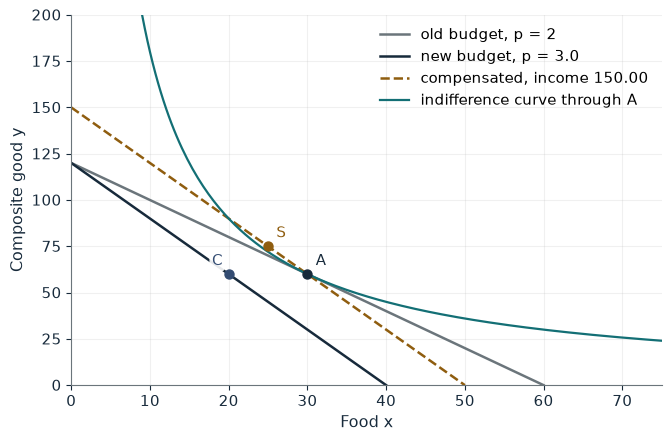

Food before (A)       30.00
Food after (C)        20.00
Compensated income    150.00
Compensated food (S)  25.00
Substitution effect   -5.00
Income effect         -5.00
Total change          -10.00

Worked steps:
  1. x before = 120 / (2 x 2) = 30.00
  2. x after = 120 / (2 x 3.0) = 20.00
  3. Slutsky income = 120 + (3.0 - 2) x 30 = 150.00
  4. Compensated x = 150.00 / (2 x 3.0) = 25.00
  5. Substitution = 25.00 - 30 = -5.00
  6. Income effect = 20.00 - 25.00 = -5.00

Ordinary demand falls from 120 / (2 x 2) = 30 to 120 / (2 x 3.0) = 20.00. Slutsky income = 120 + (3.0 - 2) x 30 = 150.00, so compensated food is 150.00 / (2 x 3.0) = 25.00. Substitution = 25.00 - 30 = -5.00 and income = 20.00 - 25.00 = -5.00; together -5.00 + (-5.00) = -10.00.


In [2]:
show(slutsky_picture(p1=3, rule='slutsky'))

Change one input, `p1`, and hold the others at the book's values:

In [3]:
sweep(slutsky_picture, 'p1', [2.5, 3, 4, 5], {'rule': 'hicksian'}, ['Compensated income', 'Substitution effect', 'Income effect'])

p1 | Compensated income | Substitution effect | Income effect
2.5 | 134.16 | -3.17 | -2.83
3 | 146.97 | -5.51 | -4.49
4 | 169.71 | -8.79 | -6.21
5 | 189.74 | -11.03 | -6.97


With Slutsky compensation the ten-unit fall splits into -5 substitution and -5 income. Hicksian compensation (income 146.97) gives -5.51 and -4.49: the two rules answer different questions. The table uses Hicksian compensation.

## 2. Hicksian-Marshallian duality: compensating and equivalent variation

Income is 100 and the transit price rises from 1. The expenditure function is $e(p,\bar u)=2\bar u\sqrt p$, so

$$e(2,50)=100\sqrt2\approx141.42, \qquad e(1,35.36)\approx70.71$$

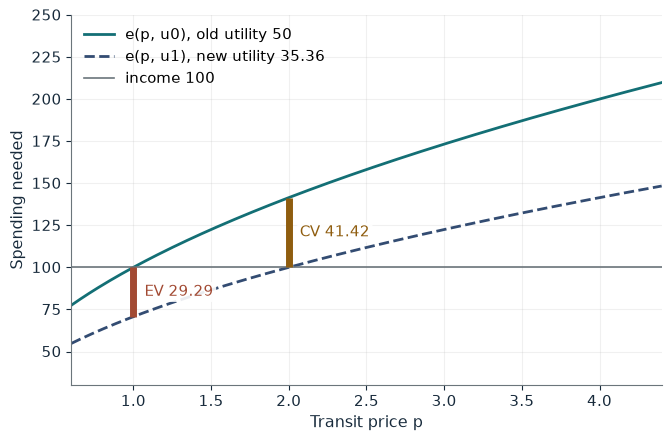

New utility u1          35.36
e(p1, 50)               141.42
Compensating variation  41.42
e(1, u1)                70.71
Equivalent variation    29.29
Hicksian bundle at p1   (35.36, 70.71)

Worked steps:
  1. x1 = 100 / (2 x 2.0) = 25.00
  2. u1 = sqrt(25.00 x 50) = 35.3553
  3. e(p1, 50) = 2 x 50 x sqrt(2.0) = 141.42
  4. CV = 141.42 - 100 = 41.42
  5. e(1, u1) = 2 x 35.3553 = 70.71
  6. EV = 100 - 70.71 = 29.29

At p = 2.0 ordinary demand is 100 / (2 x 2.0) = 25.00 rides, so u1 = sqrt(25.00 x 50) = 35.36. CV = 2 x 50 x sqrt(2.0) - 100 = 141.42 - 100 = 41.42. EV = 100 - 2 x 35.3553 x sqrt(1) = 100 - 70.71 = 29.29. CV is the larger of the two for this price rise.


In [4]:
show(variation_picture(p1=2))

Change one input, `p1`, and hold the others at the book's values:

In [5]:
sweep(variation_picture, 'p1', [1.5, 2, 3, 4], {}, ['Compensating variation', 'Equivalent variation'])

p1 | Compensating variation | Equivalent variation
1.5 | 22.47 | 18.35
2 | 41.42 | 29.29
3 | 73.21 | 42.26
4 | 100.00 | 50.00


CV is 41.42 and EV is 29.29. For every price rise shown, CV exceeds EV.

## 3. Giffen paradox: when is an inferior staple Giffen?

A hypothetical calibration (not the study's estimates):

$$\varepsilon^{M}=-0.20-(0.70)(-0.60)=0.22$$

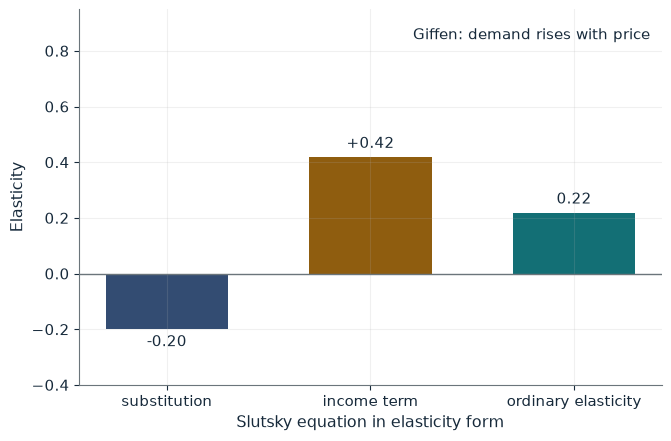

Substitution term                      -0.20
Income term -s x eta                   0.42
Ordinary elasticity                    0.22
Change in demand for a 10% price rise  2.2%
Giffen?                                yes
Threshold eta for Giffen               below -0.29

Worked steps:
  1. Income term = -(0.70) x (-0.60) = 0.42
  2. eps_M = -0.20 + 0.42 = 0.22
  3. A 10% price rise changes demand by 10 x 0.22 = 2.2%
  4. Threshold: -0.20 / 0.70 = -0.29

eps_M = -0.20 - (0.70)(-0.60) = -0.20 + 0.42 = 0.22. The income term outweighs substitution, so demand rises with price: Giffen behavior. At this budget share, Giffen behavior needs income elasticity below -0.20 / 0.70 = -0.29.


In [6]:
show(giffen_picture(share=0.7, eta=-0.6))

Change one input, `eta`, and hold the others at the book's values:

In [7]:
sweep(giffen_picture, 'eta', [-0.1, -0.3, -0.6, -0.9], {'share': 0.5}, ['Ordinary elasticity', 'Giffen?'])

eta | Ordinary elasticity | Giffen?
-0.1 | -0.15 | no
-0.3 | -0.05 | no
-0.6 | 0.10 | yes
-0.9 | 0.25 | yes


At share 0.7 and income elasticity -0.6 the ordinary elasticity is +0.22, so a 10 percent price rise raises demand by about 2.2 percent. With eta = -0.10 it is -0.13: inferior, but not Giffen. The table holds the share at 0.5, where Giffen behavior needs eta below -0.20 / 0.5 = -0.4.

## 4. Marginal analysis: add trips until the margin turns negative

Marginal benefits 900, 700, 520, 360, 220; marginal costs 300, 380, 460, 540, 620. Net increments:

$$(600,\ 320,\ 60,\ -180,\ -400)$$

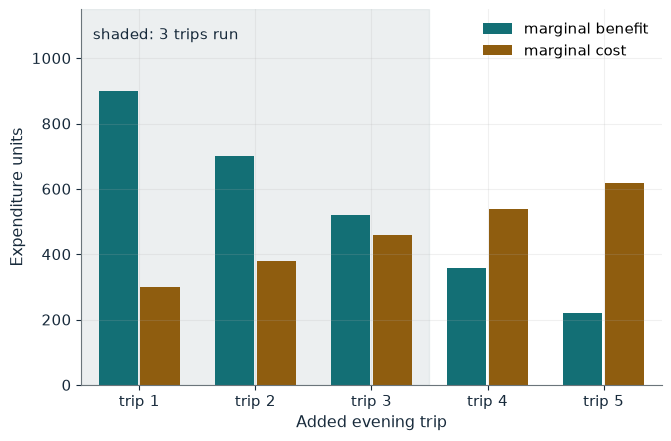

Marginal costs           300, 380, 460, 540, 620
Net increments           600, 320, 60, -180, -400
Trips run                3
Net gain from trips run  980
Depot cost               left out (sunk)

Worked steps:
  1. MC after the cut of 0: 300, 380, 460, 540, 620
  2. Net increments: 600, 320, 60, -180, -400
  3. Last trip that passes: trip 3, net 60
  4. Trip 4 fails with net -180

Net increments are MB - MC = 600, 320, 60, -180, -400. Trip 3 passes: 520 - 460 = 60. Trip 4 fails: 360 - 540 = -180. So 3 trips run.


In [8]:
show(trips_picture(cut=0, sunk='no'))

Change one input, `cut`, and hold the others at the book's values:

In [9]:
sweep(trips_picture, 'cut', [0, 100, 200, 300], {'sunk': 'no'}, ['Net increments', 'Trips run'])

cut | Net increments | Trips run
0 | 600, 320, 60, -180, -400 | 3
100 | 700, 420, 160, -80, -300 | 3
200 | 800, 520, 260, 20, -200 | 4
300 | 900, 620, 360, 120, -100 | 4


Three trips run. A cost cut of 200 gives (800, 520, 260, 20, -200) and four trips. Counting the sunk depot cost (`sunk='yes'`) changes no increment and no choice.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

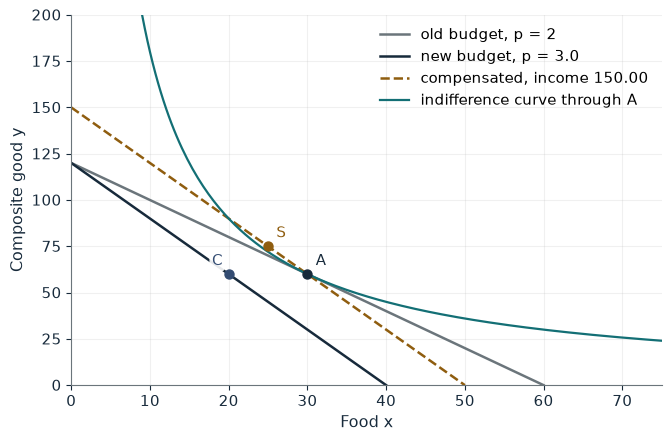

Food before (A)       30.00
Food after (C)        20.00
Compensated income    150.00
Compensated food (S)  25.00
Substitution effect   -5.00
Income effect         -5.00
Total change          -10.00

Worked steps:
  1. x before = 120 / (2 x 2) = 30.00
  2. x after = 120 / (2 x 3.0) = 20.00
  3. Slutsky income = 120 + (3.0 - 2) x 30 = 150.00
  4. Compensated x = 150.00 / (2 x 3.0) = 25.00
  5. Substitution = 25.00 - 30 = -5.00
  6. Income effect = 20.00 - 25.00 = -5.00

Ordinary demand falls from 120 / (2 x 2) = 30 to 120 / (2 x 3.0) = 20.00. Slutsky income = 120 + (3.0 - 2) x 30 = 150.00, so compensated food is 150.00 / (2 x 3.0) = 25.00. Substitution = 25.00 - 30 = -5.00 and income = 20.00 - 25.00 = -5.00; together -5.00 + (-5.00) = -10.00.


In [10]:
show(slutsky_picture(p1=3, rule='slutsky'))

## Practice

**1.** If the food price rises from 2 to 4, what are the Slutsky substitution and income effects?

<details><summary>Answer</summary>

Compensated income 120 + 2 x 30 = 180, x = 180 / 8 = 22.5, substitution -7.5; ordinary x = 15, income effect -7.5.

</details>

**2.** If the transit price rises from 1 to 4, what are CV and EV?

<details><summary>Answer</summary>

CV = 2 x 50 x sqrt(4) - 100 = 100; u1 = sqrt(12.5 x 50) = 25, so EV = 100 - 50 = 50.

</details>

**3.** With a budget share of 0.5 and income elasticity -0.3, is the staple Giffen?

<details><summary>Answer</summary>

-0.20 - (0.5)(-0.3) = -0.05 < 0, so no; Giffen needs eta below -0.4.

</details>